# Stimulus change vs. neural integration

Investigates whether segment-decoding accuracy rises with the accumulation window Δ due to
- the **brain integrating** (accumulating / denoising spikes over time) 
- **new stimulus information continuously arriving** as the movie plays
This notebook separates the two by building a stimulus-only reference, thus enabling a comparison to the neural decoding curves.

Definitions
- **Stimulus change signals**: how fast the movie itself changes: per-frame *motion energy* and the *temporal autocorrelation* (with a 1/e decorrelation time).
- **Stimulus ideal-observer decodability** `acc_stim(Δ)`: how separable the K movie segments are from the movie content seen by time Δ, using the *same* classifier as the neural decoder. <br>
  Overlaid on the neural `acc(Δ)` curves, the gap `Δ95_neural − Δ95_stim` estimates how much of each region's window is integration *beyond* the point where stimulus information has saturated.
  
This notebook reuses the extracted `.npz` tensors and the movie template, thus no NWB-files (and with that big downloads) are needed.

## Imports

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from scipy.optimize import curve_fit
from sklearn.pipeline import make_pipeline
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import StratifiedKFold, GroupKFold, cross_val_score
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier

from paths import EXTRACTED_DIR, MANIFEST, STIM_OUT_DIR


from allensdk.brain_observatory.ecephys.ecephys_project_cache import EcephysProjectCache

c:\Users\Mariu\Desktop\Scientific_Programming_Project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Config

CLF should equal to the decoder's classifier for a fair comparison.<br>
`DATA_ROOT` is absolute so the cache resolves regardless of the kernel's working directory.<br>
Figures and the neural-curve cache are stored in `stim_vs_neural/`.

In [ ]:
# stimulus parameters (must match the decoder)
MOVIE_NUMBER = 1       # 1 for natural_movie_one
FPS          = 30.0    # natural movies play at 30 frames/s (one frame is shown for ≈ 33 ms)

# must match configuration in Decoder_Analysis_Across_Regions
SEG_LEN   = 2.0        # segment length (s) that sets the number of classes K and the maximum length for an accumulation window
N_DELTAS  = 14         # number of Δ windows
N_SPLITS  = 5          # number of CV folds
MIN_UNITS = 10         # min units for a (session, region) to be decoded
CLF       = "lda"  # classifier id string (must equal the decoder's CLF for a fair comparison)
RANDOM_SEED = 0        # random seed for reproducibility

# stimulus-feature extraction
DS_STRIDE = 8          # spatial downsample stride on the movie frames
N_PCA     = 40         # PCA dimensions for the frame features

# Areas in ascending hierarchy order
REGIONS = ["VISp", "VISl", "VISrl", "VISal", "VISpm", "VISam"]
# Okabe-Ito palette
REGION_COLORS = {"VISp":"#0072B2","VISl":"#E69F00","VISal":"#009E73",
                 "VISrl":"#D55E00","VISam":"#CC79A7","VISpm":"#56B4E9"}
STIM_COLOR = "#1F2933"

# plotting parameters
plt.rcParams.update({"figure.dpi":110, "axes.spines.top":False, "axes.spines.right":False,
                     "axes.grid":True, "grid.alpha":0.25, "font.size":10})

# defines classifiers
def make_clf():
    """Same classifier zoo as the decoder, so neural and stimulus use the same model family."""
    if CLF == "lda":     return make_pipeline(StandardScaler(), LDA(solver="lsqr", shrinkage="auto"))
    if CLF == "logreg":  return make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, C=1.0))
    if CLF == "rf":      return make_pipeline(StandardScaler(), RandomForestClassifier(
                             n_estimators=500, min_samples_leaf=2, max_features="sqrt", random_state=RANDOM_SEED))
    if CLF == "svm-rbf": return make_pipeline(StandardScaler(), SVC(kernel="rbf", C=5.0, gamma="scale", random_state=RANDOM_SEED))
    if CLF == "hgb":     return make_pipeline(StandardScaler(), HistGradientBoostingClassifier(
                             max_depth=3, learning_rate=0.1, max_iter=200, random_state=RANDOM_SEED))
    if CLF == "knn":     return make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
    if CLF == "mlp":     return make_pipeline(StandardScaler(), MLPClassifier(
                             hidden_layer_sizes=(128,), alpha=1e-2, max_iter=1000, random_state=RANDOM_SEED))
    raise ValueError(f"unknown CLF {CLF!r}")  # raises an error if unknown CLF string is provided

def saturate(x, a_0, ainf, tau):
    """
    Saturating exponential: rises from a_0 to asymptote ainf with time-constant tau.
    """
    return ainf - (ainf - a_0) * np.exp(-x / tau)

def fit_window(deltas, accs, chance):
    """
    Fits the saturating curve
    Returns tau and Δ95 = 3*tau
    NaNs in accs are dropped first."""
    deltas = np.asarray(deltas, float); accs = np.asarray(accs, float)
    ok = np.isfinite(accs)
    if ok.sum() < 3:
        return None
    d, a = deltas[ok], accs[ok]
    p0 = [max(a[0], chance), max(a[-1], a[0] + 1e-3), d[-1] / 3]
    try:
        popt, _ = curve_fit(saturate, d, a, p0=p0,
                            bounds=([0, 0, 1e-3], [1, 1, d[-1]*5]), maxfev=20000)
        return dict(a0=popt[0], ainf=popt[1], tau=popt[2], d_95=3.0*popt[2])
    except Exception:
        return None

def gain_and_d95(deltas, accs, chance):
    """
    Robust Δ95 + a 0→1 normalized gain curve for one accuracy curve.
    Uses the saturating fit when it rises meaningfully (matches the decoder's 3*tau);
    otherwise (flat / already-saturated / fit failed) falls back to the empirical window
    where accuracy first reaches 95% of its observed gain. Returns (d95, gain, fit).
    """
    deltas = np.asarray(deltas, float)
    accs = np.asarray(accs, float)
    ok = np.isfinite(accs)
    fit = fit_window(deltas, accs, chance)
    if fit is not None and (fit["ainf"] - fit["a0"]) > 0.02:
        a0, ainf, d95 = fit["a0"], fit["ainf"], fit["d_95"]
    else:                                                   # flat / tiny-gain / unfittable
        a0 = float(np.nanmin(accs[ok])) if ok.any() else chance
        ainf = float(np.nanmax(accs[ok])) if ok.any() else a0 + 1e-3
        thr = a0 + 0.95 * (ainf - a0)
        hit = np.where(ok & (accs >= thr))[0]
        d95 = float(deltas[hit[0]]) if len(hit) else float(deltas[ok][-1])
    gain = (accs - a0) / (ainf - a0) if (ainf - a0) > 1e-6 else np.where(ok, 1.0, np.nan)
    return d95, gain, fit

## Movie loading & computation of the segmentation / Δ grid

The segment length, number of classes `K`, and Δ grid are computed exactly as in
`Analysis_Decoder_AcrossRegions`, so the stimulus and neural analyses share one coordinate system.<br>
`K` is capped so the same number of segments fits both the shortest session and the movie.

In [ ]:
# loads the movie template
cache = EcephysProjectCache.from_warehouse(manifest=str(MANIFEST))
movie = cache.get_natural_movie_template(MOVIE_NUMBER)  # (n_frames, H, W) grayscale uint8
n_frames_movie = movie.shape[0]
print(f"movie template: {movie.shape}  (~{n_frames_movie/FPS:.1f}s at {FPS:.0f} fps)")

# derives (from the extracted sessions) the same segmentation (Δ-grid) that the decoder uses
def _load_npz(path):
    session_data = np.load(path, allow_pickle=True)
    return dict(counts=session_data["counts"], regions=np.asarray(session_data["regions"]).astype(str),
                bin_size=float(session_data["bin_size"]), session_id=int(session_data["session_id"]))

sessions = sorted(EXTRACTED_DIR.glob("session_*.npz"))
bin_size = _load_npz(sessions[0])["bin_size"]                     # 10 ms
num_bins_perseg = int(round(SEG_LEN / bin_size))                  # bins per segment (neural)
minb = min(_load_npz(p)["counts"].shape[1] for p in sessions)     # shortest session (bins)
frames_per_seg = int(round(SEG_LEN * FPS))                        # frames per segment (stimulus)

# K = largest #segments that fit in BOTH the shortest session and the movie, so chance matches everywhere
K = int(min(minb // num_bins_perseg, n_frames_movie // frames_per_seg))
CHANCE = 1.0 / K

# Δ grid in seconds (identical construction to the decoder)
# yields 14 evenly spaced window lengths from the first bin (0.01s) up to the full 2 s (step ≈ 0.153 s), each rounded to the nearest whole 10 ms bin
DELTAS = np.unique(np.clip(np.round(np.linspace(bin_size, SEG_LEN, N_DELTAS) / bin_size).astype(int),
                           1, num_bins_perseg)) * bin_size
print(f"segment={SEG_LEN}s | K={K} classes (chance={CHANCE:.3f}) | "
      f"{len(DELTAS)} Δ values {DELTAS[0]*1000:.0f}-{DELTAS[-1]*1000:.0f} ms")

c:\Users\Mariu\Desktop\Scientific_Programming_Project\.venv\Lib\site-packages\allensdk\brain_observatory\ecephys\ecephys_project_cache.py:770: UserWarning: Reading `.npy` or `.npz` file required additional header parsing as it was created on Python 2. Save the file again to speed up loading and avoid this warning.
  return np.load(path, allow_pickle=False)


movie template: (900, 304, 608)  (~30.0s at 30 fps)
segment=2.0s | K=15 classes (chance=0.067) | 14 Δ values 10-2000 ms


## Analysis 1: Stimulus change signals

**Motion energy** `d(t)` = mean absolute pixel difference between consecutive frames (high during cuts / fast motion).<br>
**Temporal autocorrelation** = mean pixel-correlation between frames τ apart, its<br>
**1/e decorrelation time** is the single-number "how long the image stays similar to itself", to compare against the neural `Δ95`.

In [ ]:
def motion_energy(movie):
    """
    Per-frame visual change: mean absolute pixel difference between consecutive frames.
    Returns an array of length n_frames-1; entry t = change from frame t to frame t+1.
    High during cuts / fast motion, low during static stretches.
    """
    movie = movie.astype(np.float32)
    return np.abs(np.diff(movie, axis=0)).mean(axis=(1, 2)) / 255 * 100

def temporal_autocorrelation(movie, max_lag_frames):
    """
    Stimulus temporal autocorrelation: average Pearson correlation (across pixels)
    between frame t and frame t+tau, over all t, for each lag tau = 0..max_lag_frames.
    Measures how long the image stays similar to itself.
    """
    float_movie = movie.reshape(movie.shape[0], -1).astype(np.float32)
    float_movie = float_movie - float_movie.mean(axis=1, keepdims=True)                 # center each frame
    norms = np.linalg.norm(float_movie, axis=1) + 1e-9  # contains euclidean norm of the frame's centered pixel-value vector
    autocorrelation_list = [1.0]

    # iterates over all lags
    for tau in range(1, max_lag_frames + 1):
        a, b = float_movie[:-tau], float_movie[tau:]  # a conntains frame up to the last tau frames, b contains frames starting from there
        autocorrelation_list.append(float(np.mean((a * b).sum(1) / (norms[:-tau] * norms[tau:]))))
    return np.array(autocorrelation_list)

def decorrelation_time(autocorrelation, fps, level=np.exp(-1)):
    """First lag (in seconds) at which the autocorrelation drops to `level` (default 1/e)."""
    below = np.where(autocorrelation <= level)[0]
    if len(below) == 0:
        return np.nan
    i = below[0]
    if i == 0:
        return 0.0
    # linear interpolation between lag i-1 and i for a smoother crossing estimate
    frac = (autocorrelation[i-1] - level) / (autocorrelation[i-1] - autocorrelation[i] + 1e-12)
    return (i - 1 + frac) / fps

# compute the two stimulus-change signals
motion_energy = motion_energy(movie)                  # len n_frames-1
MAX_LAG = int(round(SEG_LEN * FPS))                   # look out to one segment length
auto_corr = temporal_autocorrelation(movie, MAX_LAG)  # len MAX_LAG+1
lags_s = np.arange(len(auto_corr)) / FPS
tau_decorr = decorrelation_time(auto_corr, FPS)       # seconds to 1/e

print(f"stimulus decorrelation time (1/e) ≈ {tau_decorr*1000:.0f} ms")

stimulus decorrelation time (1/e) ≈ nan ms


saved stim_vs_neural\stimulus_change_signals.png


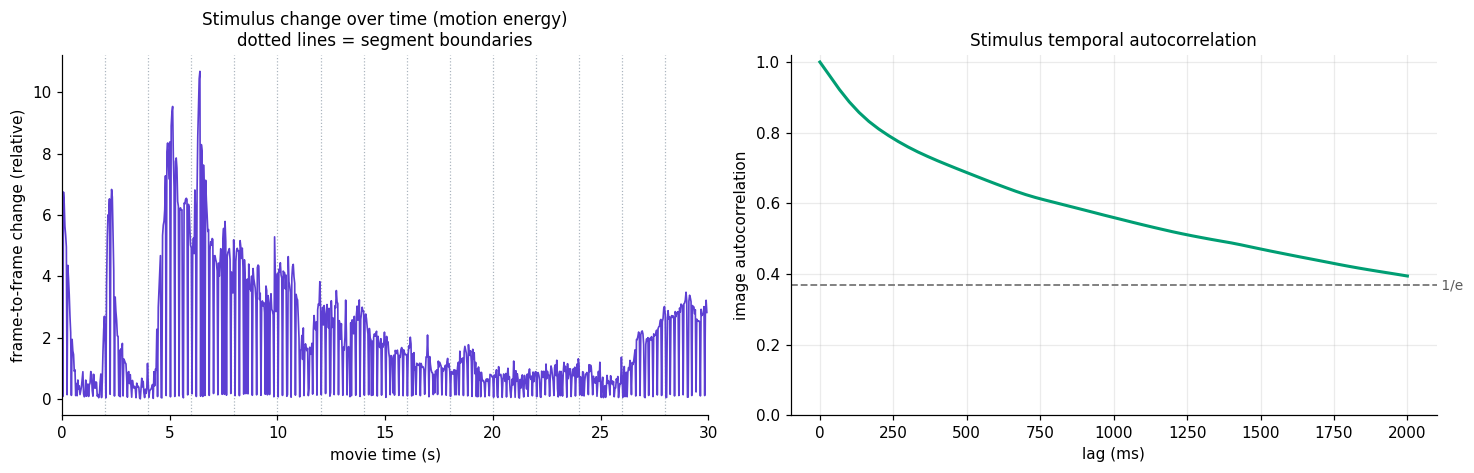

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.4))

# left: motion energy over movie time, with segment boundaries
time_motion_energy = np.arange(len(motion_energy)) / FPS
axes[0].plot(time_motion_energy, motion_energy, color="#5D3FD3", lw=1.1)  # "#0072B2"
for k in range(1, K):
    axes[0].axvline(k * SEG_LEN, color="#AAB4BE", lw=0.8, ls=":", zorder=0)
axes[0].set_xlabel("movie time (s)")
axes[0].set_ylabel("frame-to-frame change (relative)")
axes[0].set_title("Stimulus change over time (motion energy)\ndotted lines = segment boundaries", fontsize=11)
axes[0].set_xlim(0, K * SEG_LEN)

# right: temporal autocorrelation vs lag, with the 1/e decorrelation time
axes[1].plot(lags_s * 1000, auto_corr, color="#009E73", lw=2)
axes[1].axhline(np.exp(-1), color="#7A7A7A", ls="--", lw=1.2)
axes[1].text(axes[1].get_xlim()[1], np.exp(-1), " 1/e", va="center", color="#5A5A5A", fontsize=9)

if np.isfinite(tau_decorr):
    axes[1].axvline(tau_decorr*1000, color=STIM_COLOR, lw=1.6, ls="-")
    axes[1].text(tau_decorr*1000, 0.9, f" τ ≈ {tau_decorr*1000:.0f} ms", color=STIM_COLOR, fontsize=9.5, fontweight="bold")
axes[1].set_xlabel("lag (ms)")
axes[1].set_ylabel("image autocorrelation")
axes[1].set_title("Stimulus temporal autocorrelation", fontsize=11)
axes[1].set_ylim(0, 1.02)

fig.tight_layout()
fig.savefig(STIM_OUT_DIR / "stimulus_change_signals.png", dpi=150, bbox_inches="tight")
print("saved", STIM_OUT_DIR / "stimulus_change_signals.png")
axes[0].grid(False)

plt.show()

## Analysis 2: Stimulus ideal-observer decodability `acc_stim(Δ)`

At each window Δ, the first `round(Δ·fps)` frames of each segment are taken, labeled by segment, and the same classifier as the neural decoder uses is used for cross-validation on the stimulus-only data. This yields the *stimulus information available by time Δ*, which represents a ceiling to compare the neural curve against.

Notes: 
- Using repeats as samples would make every sample a perfect duplicate → trivial, instead individual frames within the window are used and not trial repeats
- Absolute accuracy of repeats vs frames (or rather spike counts vs PCA from pixels) isn't directly comparable. What can be compared is the shape / saturation timing, displayed as the normalized gain
- If the movie segments are so visually distinct that even a handful of frames already identify them, then acc_stim(Δ) is already ≈ 1.0 at the smallest Δ and just stays flat → gain_and_d95 falls back to an empirical Δ95: the first window where accuracy reaches 95% of its (tiny) observed gain

In [ ]:
def block_mean(frames, b):  # frames: (n, H, W)
    """
    Computes the block-wise mean of the frames, downsampling by a factor of b in both height and width.
    frames: (n, H, W) array of frames
    b: block size (integer)
    Returns an array of shape (n, H//b, W//b).
    """
    n, H, W = frames.shape # n = number of frames, H = height, W = width
    H2, W2 = H // b, W // b
    cropped = frames[:, :H2*b, :W2*b]  # crops to a size evenly divisible by b
    return cropped.reshape(n, H2, b, W2, b).mean(axis=(2, 4))  # mean averages over the b x b blocks

def frame_features(movie, ds=DS_STRIDE, n_pca=N_PCA, seed=RANDOM_SEED):
    """
    Turns each movie frame into a compact feature vector by spatially downsampling
    (spatial stride ds), flattening, z-scoring across frames and then applying PCA
    Returns (n_frames, n_comp).
    """
    X = block_mean(movie.astype(np.float32), ds).reshape(movie.shape[0], -1)  # downsampling to ensure fast PCA
    X = StandardScaler().fit_transform(X)  # PCA to further reduce input dimensionality and remove correlations between pixels, prevent overfitting, and speed up the classifier training
    n_comp = int(min(n_pca, X.shape[1], X.shape[0] - 1))  # ensures there are no more components than features or samples − 1
    return PCA(n_components=n_comp, random_state=seed).fit_transform(X)

def stim_decodability(features, K, frames_per_seg, deltas, fps, n_splits):
    """
    Ideal-observer segment decodability from the stimulus alone, matched to the neural
    decoder's segment-classification.
    At each window Δ, takes the first round(Δ*fps) frames of each of the K segments, labels
    them by segment, and cross-validates the same classifier.
    Returns an accuracy per Δ (NaN where a window has too few frames to cross-validate).

    features: (n_frames, n_comp) array of movie-frame features
    K: number of segments (classes)
    frames_per_seg: number of frames per segment (for indexing)
    deltas: array of Δ values (in seconds) to evaluate
    fps: frames per second of the movie
    n_splits: number of cross-validation folds

    Interpretation: how separable the segments are from the movie content seen by time Δ
    which is the stimulus-information ceiling to compare the neural accuracy curve against.
    """
    accs = []  # for storing the accuracies per window
    # iterates over time steps
    for dt in deltas:
        # number of frames to use for this window Δ (at least 1)
        num_frames = max(1, int(round(dt * fps)))
        features_list, labels_list = [], []

        # iterates over each segment
        for k in range(K):
            first_frames = features[k*frames_per_seg : k*frames_per_seg + num_frames]   # first num_frames frames of segment k
            features_list.append(first_frames)  # all frame features for segment k
            labels_list.append(np.full(len(first_frames), k))  # labels for segment k

        # Stacks all segments into one design matrix (K·num_frames, n_comp) and label vector
        X = np.vstack(features_list)
        y = np.concatenate(labels_list)
        per_class = np.bincount(y, minlength=K).min()  # smallest class count, used to check if cross-validation is possible)

        if per_class < 2:  # if cross-validation is not possible (not enough samples per class), append NaN and continue to the next delta
            accs.append(np.nan)
            continue

        num_cv_splits = int(min(n_splits, per_class))  # number of splits for cross-validation (can't exceed the smallest class count)
        cv = StratifiedKFold(n_splits=num_cv_splits, shuffle=True, random_state=RANDOM_SEED)  # cross-validation, stratified, not group k-fold because the samples are frames with no group to hold out
        accs.append(cross_val_score(make_clf(), X, y, cv=cv, scoring="accuracy").mean())  # scores the cross-validation and appends the accuracies
    return np.array(accs)

features = frame_features(movie)  # (n_frames, n_comp)
# computes the stimulus decodability curve (accuracy vs Δ)
acc_stim = stim_decodability(features, K, frames_per_seg, DELTAS, FPS, N_SPLITS)
# computes the Δ95, gain, and fit for the stimulus decodability curve
d95_stim, gain_stim, fit_stim = gain_and_d95(DELTAS, acc_stim, CHANCE)

# prints the stimulus decodability results
print(f"stimulus acc(Δ): {np.nanmin(acc_stim):.2f} → {np.nanmax(acc_stim):.2f}  "
      f"| Δ95_stim ≈ {d95_stim*1000:.0f} ms"
      + ("" if fit_stim and (fit_stim['ainf']-fit_stim['a0'])>0.02 else "  (empirical; stimulus ~flat/early-saturating)"))

stimulus acc(Δ): 0.99 → 1.00  | Δ95_stim ≈ 160 ms  (empirical; stimulus ~flat/early-saturating)


## Neural decoding curves (recomputed from extracted data, cached)

Reuses the decoder's exact segment-classification logic to get each region's mean `acc(Δ)` across mice. The first run decodes every session (minutes, esp. with `svm-rbf`) and caches the curves to `stim_vs_neural/neural_curves_<CLF>.npz`; later runs load instantly.<br>
For a quick look, `CLF = "lda"` or a small `SESSION_LIMIT` in the config have short runtimes and the cache file should be deleted.

In [ ]:
# neural decoding curves per region, reusing the decoder logic from Decoder_Analysis_Across_Regions
# (recomputed here so the notebook is self-contained, cached to OUT_DIR so re-runs are instant)

def region_counts(session, region):
    """
    Selects only the specified region's units, 
    and only the first K*nbps bins (whole segments).
    """
    mask = session["regions"] == region
    return session["counts"][:, :K*num_bins_perseg, mask]  # [repeat, K*nbps, n_region_units]

def accumulated_features(spike_count_data, n_delta):
    """
    Builds the decoding matrix for one accumulation window of ndelta bins.
    spike_count_data : [repeat, K*nbps, unit]
    Reshapes time points into (segment, within-segment-bin),
    Sums spikes from each segment's onset up to ndelta (window length) bins  
    Returns one feature vector (per unit),  per (repeat, segment)
      data: summed spike counts with one row per repeat/segment, one column per unit
      seg_id: segment ID of each row (target class for prediction by decoder)
      repeat_id: repeat ID for each row, used by cross-validation to hold out entire repeats
    """
    
    repeat_count, _, unit_count = spike_count_data.shape
    spike_counts_reshaped = spike_count_data.reshape(repeat_count, K, num_bins_perseg, unit_count)[:, :, :n_delta, :].sum(2)    # [repeat, segment, unit]
    data = spike_counts_reshaped.reshape(repeat_count*K, unit_count).astype(float)  # rows = (repeat, segment) trials
    seg_id = np.tile(np.arange(K), repeat_count)       # class label = segment id
    repeat_id = np.repeat(np.arange(repeat_count), K)  # group = repeat (for CV)
    return data, seg_id, repeat_id

def decode_curve(spike_count_data):
    """
    Cross-validated segment-decoding accuracy at each Δ in DELTAS.
    GroupKFold holds out whole repeats, so the classifier is always tested on
    repeats it never trained on (no trial leakage between train and test).
    """
    cv = GroupKFold(n_splits=min(N_SPLITS, spike_count_data.shape[0]))  # set up GroupKFold split
    acc_features = []
    for dt in DELTAS:
        n_delta = int(np.clip(round(dt / bin_size), 1, num_bins_perseg)) # bin count for the current time window dt            # window length in bins
        data, seg_id, repeat_id = accumulated_features(spike_count_data, n_delta)
        acc_features.append(cross_val_score(make_clf(), data, seg_id, groups=repeat_id, cv=cv, scoring="accuracy").mean())  # mean CV accuracy at this Δ (parallelism is handled per-session in the Run cell)
    return np.array(acc_features)

NEURAL_CACHE = STIM_OUT_DIR / f"neural_curves_{CLF}.npz"

# uses cached neural curves if they exist
if NEURAL_CACHE.exists():
    cached_curve = np.load(NEURAL_CACHE, allow_pickle=True)
    neural_curves = {region: cached_curve[region] for region in REGIONS if region in cached_curve.files}  # region -> [n_sessions, len(DELTAS)]
    print(f"Loaded cached neural curves from {NEURAL_CACHE}")
# otherwise computes them from the extracted sessions
else:
    neural_curves = {region: [] for region in REGIONS}  # dict mapping for each region
    for session_index, path in enumerate(sessions, 1):
        session = _load_npz(path)
        # iterates over visual regions
        for region in REGIONS:
            region_count = region_counts(session, region)  # extracts the spike counts for the current region
            # number of units in the region must be >= MIN_UNITS and number of repeats must be >= N_SPLITS to compute the decoding curve
            if region_count.shape[2] >= MIN_UNITS and region_count.shape[0] >= N_SPLITS:
                neural_curves[region].append(decode_curve(region_count))  # computes the actual decoding curve for the current region and appends it to the list
        # success output
        print(f"  [{session_index}/{len(sessions)}] session {session['session_id']} done")

    neural_curves = {region: np.array(val) for region, val in neural_curves.items() if len(val)}  # converts the lists of curves to numpy arrays for each region, filtering out regions with no curves
    np.savez_compressed(NEURAL_CACHE, **neural_curves)  # saves the neural curves to a compressed npz file
    print(f"saved neural curves -> {NEURAL_CACHE}")  # saving success message

# extracts per-region mean curve across mice + robust Δ95 / normalized gain from the mean curve
neural_mean, neural_gain, d95_neural = {}, {}, {}
for region in neural_curves:
    neural_mean[region] = np.nanmean(neural_curves[region], axis=0)
    d95_neural[region], neural_gain[region], _ = gain_and_d95(DELTAS, neural_mean[region], CHANCE)

# prints the neural decodability results
print({result: round(d95_neural[result]*1000) for result in d95_neural})

  [1/30] session 715093703 done


c:\Users\Mariu\Desktop\Scientific_Programming_Project\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
c:\Users\Mariu\Desktop\Scientific_Programming_Project\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
c:\Users\Mariu\Desktop\Scientific_Programming_Project\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
c:\Users\Mariu\Desktop\Scientific_Programming_Project\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (10

  [2/30] session 719161530 done
  [3/30] session 721123822 done


c:\Users\Mariu\Desktop\Scientific_Programming_Project\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
c:\Users\Mariu\Desktop\Scientific_Programming_Project\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
c:\Users\Mariu\Desktop\Scientific_Programming_Project\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
c:\Users\Mariu\Desktop\Scientific_Programming_Project\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (10

  [4/30] session 732592105 done


...

  [26/30] session 773418906 done


c:\Users\Mariu\Desktop\Scientific_Programming_Project\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
c:\Users\Mariu\Desktop\Scientific_Programming_Project\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
c:\Users\Mariu\Desktop\Scientific_Programming_Project\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
c:\Users\Mariu\Desktop\Scientific_Programming_Project\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (10

  [27/30] session 791319847 done


c:\Users\Mariu\Desktop\Scientific_Programming_Project\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
c:\Users\Mariu\Desktop\Scientific_Programming_Project\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
c:\Users\Mariu\Desktop\Scientific_Programming_Project\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
c:\Users\Mariu\Desktop\Scientific_Programming_Project\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (10

  [28/30] session 797828357 done
  [29/30] session 798911424 done
  [30/30] session 799864342 done
saved neural curves -> stim_vs_neural\neural_curves_mlp.npz
{'VISp': 410, 'VISl': 580, 'VISrl': 684, 'VISal': 521, 'VISpm': 657, 'VISam': 672}


## Overlay: Neural Decoding Curve vs Stimulus
- Left: raw accuracy curves (neural per area + stimulus).
- Right: each curve rescaled to its own 0→1 gain so the *timing* is comparable, with Δ95 marked.<br>
Neural Δ95 to the right of the stimulus curve ⇒ the region keeps integrating after the stimulus has stopped delivering new information (neural dynamics / denoising); neural *tracking* the stimulus ⇒ accuracy is stimulus-information-limited.

saved stim_vs_neural\stimulus_vs_neural_mlp.png


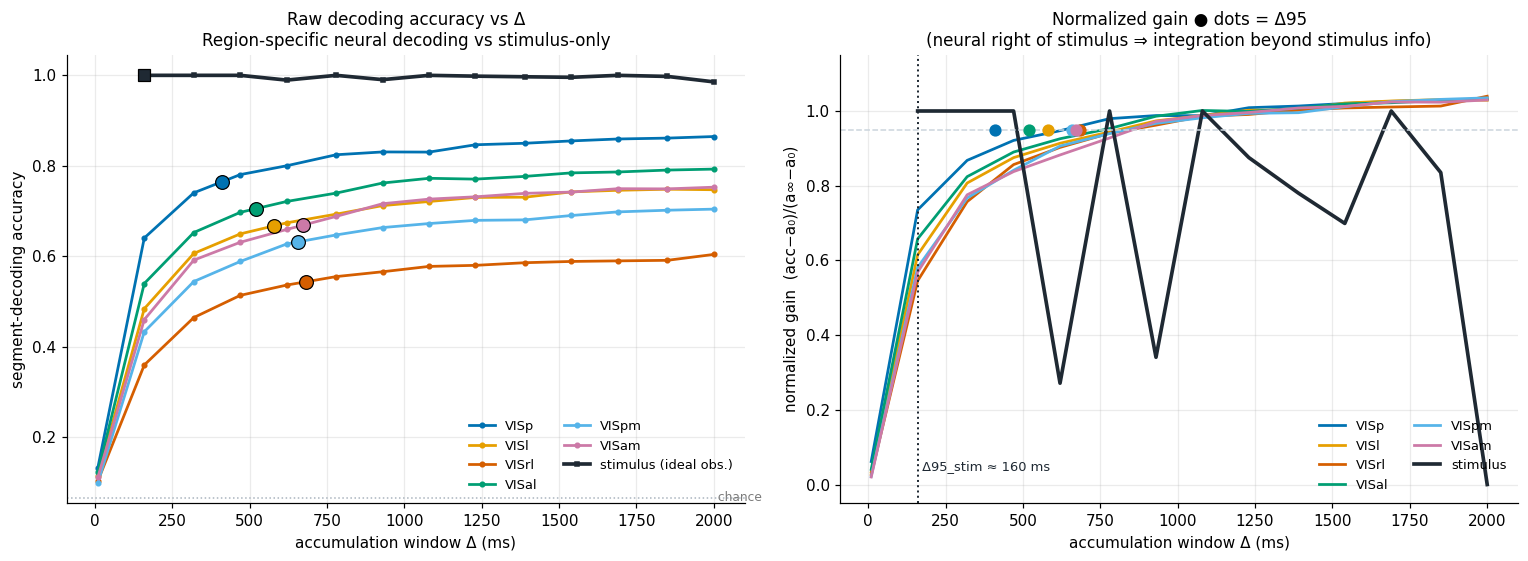

region  d95_neural_ms  d95_stim_ms  gap_ms  stim_decorr_ms
  VISp            410          160     250             NaN
  VISl            580          160     420             NaN
 VISrl            684          160     524             NaN
 VISal            521          160     361             NaN
 VISpm            657          160     497             NaN
 VISam            672          160     512             NaN

gap_ms = Δ95_neural − Δ95_stim : positive ⇒ the region keeps integrating after the stimulus information has saturated (neural dynamics / denoising rather than new content).


In [ ]:
deltas_ms = DELTAS * 1000  # converts deltas to milliseconds for plotting

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))

# Left Panel: raw accuracy curves, neural per region + stimulus
ax = axes[0]
# iterates over the regions
for region in REGIONS:
    # plots the mean neural decoding accuracy for each region
    if region in neural_mean:
        ax.plot(deltas_ms, neural_mean[region], color=REGION_COLORS[region], lw=1.8, marker="o", ms=3, label=region)
        if d95_neural[region] <= DELTAS[-1]:                      # skip a runaway fit off the x-axis
            acc_at_d95 = np.interp(d95_neural[region], DELTAS, neural_mean[region])
            ax.plot(d95_neural[region] * 1000, acc_at_d95, "o", color=REGION_COLORS[region],
                    ms=9, markeredgecolor="k", markeredgewidth=0.8, zorder=6)

ax.plot(deltas_ms, acc_stim, color=STIM_COLOR, lw=2.4, ls="-", marker="s", ms=3, label="stimulus (ideal obs.)")
stim_finite = np.isfinite(acc_stim)                          # drops the NaN at Δ=10 ms before interpolating
if np.isfinite(d95_stim) and d95_stim <= DELTAS[-1]:
    acc_stim_at_d95 = np.interp(d95_stim, DELTAS[stim_finite], acc_stim[stim_finite])
    ax.plot(d95_stim * 1000, acc_stim_at_d95, "s", color=STIM_COLOR,
            ms=8, markeredgecolor="k", markeredgewidth=0.8, zorder=6)
ax.axhline(CHANCE, color="#AAB4BE", lw=1, ls=":")
ax.text(deltas_ms[-1], CHANCE, " chance", va="center", color="#7A7A7A", fontsize=8)
ax.set_xlabel("accumulation window Δ (ms)")
ax.set_ylabel("segment-decoding accuracy")
ax.set_title("Raw decoding accuracy vs Δ\nRegion-specific neural decoding vs stimulus-only", fontsize=11)
ax.legend(frameon=False, fontsize=8.5, ncol=2, loc="lower right")

# Right Panel: normalized gain curves (shape/timing) with Δ95 markers
ax = axes[1]
# iterates over regions
for region in REGIONS:
    # iterates over the neural gains
    if region in neural_gain:
        ax.plot(deltas_ms, neural_gain[region], color=REGION_COLORS[region], lw=1.8, label=region)
        if d95_neural[region] <= DELTAS[-1]*1.5:
            ax.plot(d95_neural[region]*1000, 0.95, "o", color=REGION_COLORS[region], ms=7, zorder=5)
ax.plot(deltas_ms, gain_stim, color=STIM_COLOR, lw=2.4, ls="-", label="stimulus")

if np.isfinite(d95_stim):
    ax.axvline(d95_stim*1000, color=STIM_COLOR, lw=1.3, ls=":")
    ax.text(d95_stim*1000, 0.04, f" Δ95_stim ≈ {d95_stim*1000:.0f} ms", color=STIM_COLOR, fontsize=8.5)

ax.axhline(0.95, color="#CBD5DD", lw=1, ls="--")
ax.set_xlabel("accumulation window Δ (ms)")
ax.set_ylabel("normalized gain  (acc−a₀)/(a∞−a₀)")
ax.set_title("Normalized gain ● dots = Δ95\n(neural right of stimulus ⇒ integration beyond stimulus info)", fontsize=11)
ax.set_ylim(-0.05, 1.15)
ax.legend(frameon=False, fontsize=8.5, ncol=2, loc="lower right")

fig.tight_layout()
fig.savefig(STIM_OUT_DIR / f"stimulus_vs_neural_{CLF}.png", dpi=150, bbox_inches="tight")
print("saved", STIM_OUT_DIR / f"stimulus_vs_neural_{CLF}.png")
plt.show()

# creates summary table showing the per-region Δ95 vs stimulus references
rows = []
for region in REGIONS:
    if region in d95_neural:
        rows.append(dict(region=region,
                         d95_neural_ms=round(d95_neural[region]*1000),
                         d95_stim_ms=round(d95_stim*1000) if np.isfinite(d95_stim) else np.nan,
                         gap_ms=round((d95_neural[region]-d95_stim)*1000) if np.isfinite(d95_stim) else np.nan,
                         stim_decorr_ms=round(tau_decorr*1000) if np.isfinite(tau_decorr) else np.nan))

summary = pd.DataFrame(rows)
summary.to_csv(STIM_OUT_DIR / f"stimulus_vs_neural_d95_{CLF}.csv", index=False)

print(summary.to_string(index=False))
print("\ngap_ms = Δ95_neural − Δ95_stim : positive ⇒ the region keeps integrating after the "
      "stimulus information has saturated (neural dynamics / denoising rather than new content).")

## PCA Analysis on only the stimulus

In [ ]:
def fed_frame_indices(K, frames_per_seg, num_frames):
    """
    Row indices of the first num_frames frames of each of the K segments (onset-anchored).
    """
    return np.concatenate([k * frames_per_seg + np.arange(num_frames) for k in range(K)])

def pca_on_fed_frames(movie, K, frames_per_seg, num_frames, ds=DS_STRIDE, n_pca=N_PCA, seed=RANDOM_SEED):
    """
    Fits PCA on only the frames the stimulus decoder sees at a window of nf frames 
    (the first nf frames of each segment)
    Returns:
      Z       : [K*nf, n_comp]  PCA coordinates of those frames
      seg_id  : [K*nf]          segment label per frame (for colouring)
      pca     : the fitted PCA  (for explained_variance_ratio_)
    """
    idx = fed_frame_indices(K, frames_per_seg, num_frames)                   # which movie frames are fed
    X = movie[idx][:, ::ds, ::ds].reshape(len(idx), -1).astype(np.float32)   # downsample + flatten
    X = StandardScaler().fit_transform(X)

    n_comp = int(min(n_pca, X.shape[1], X.shape[0] - 1))  # number of pca components
    pca = PCA(n_components=n_comp, random_state=seed)
    Z = pca.fit_transform(X)

    seg_id = np.repeat(np.arange(K), num_frames)                             # 0..K-1, num_frames times each
    
    return Z, seg_id, pca

5 frames/segment × 15 segments = 75 frames | PC1-2 explain 37.5%
entire PCA (40 PCs): 0.726
PC1 & PC2:               0.874
PC1-10:                  0.914


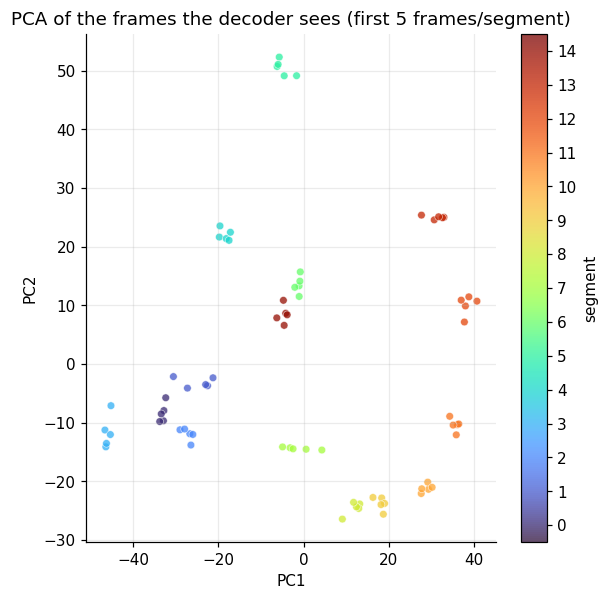

In [ ]:
num_frames = max(1, int(round(0.16 * FPS)))          # = 5 frames, the first window the decoder scores
Z, seg_id, pca = pca_on_fed_frames(movie, K, frames_per_seg, num_frames)

print(f"{num_frames} frames/segment × {K} segments = {len(seg_id)} frames | "
      f"PC1-2 explain {100 * pca.explained_variance_ratio_[:2].sum():.1f}%")

# Print Silhouette scores
print(f"entire PCA ({Z.shape[1]} PCs): {silhouette_score(Z, seg_id):.3f}")   # 0.726
print(f"PC1 & PC2:               {silhouette_score(Z[:, :2], seg_id):.3f}")   # 0.874
print(f"PC1-10:                  {silhouette_score(Z[:, :10], seg_id):.3f}")

# small, display-only jitter to avoid overplotting in the PCA scatter plot
rng = np.random.default_rng(0)
jitter_frac = 0.015
jx = rng.normal(0, jitter_frac * np.ptp(Z[:, 0]), len(Z))   # np.ptp = max - min
jy = rng.normal(0, jitter_frac * np.ptp(Z[:, 1]), len(Z))

plt.figure(figsize=(6, 6))
sc = plt.scatter(Z[:, 0] + jx, Z[:, 1] + jy, c=seg_id, cmap="turbo", s=25,
                 alpha=0.75, edgecolors="white", linewidths=0.4,
                 vmin=-0.5, vmax=K-0.5)
plt.colorbar(sc, label="segment", ticks=range(0, K, max(1, K // 8)))
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title(f"PCA of the frames the decoder sees (first {num_frames} frames/segment)")
plt.show()

Variance explained by first 10 PCs for 5 frames/seg: 85.5%
Variance explained by first 10 PCs for 15 frames/seg: 75.7%
Variance explained by first 10 PCs for 60 frames/seg: 67.1%


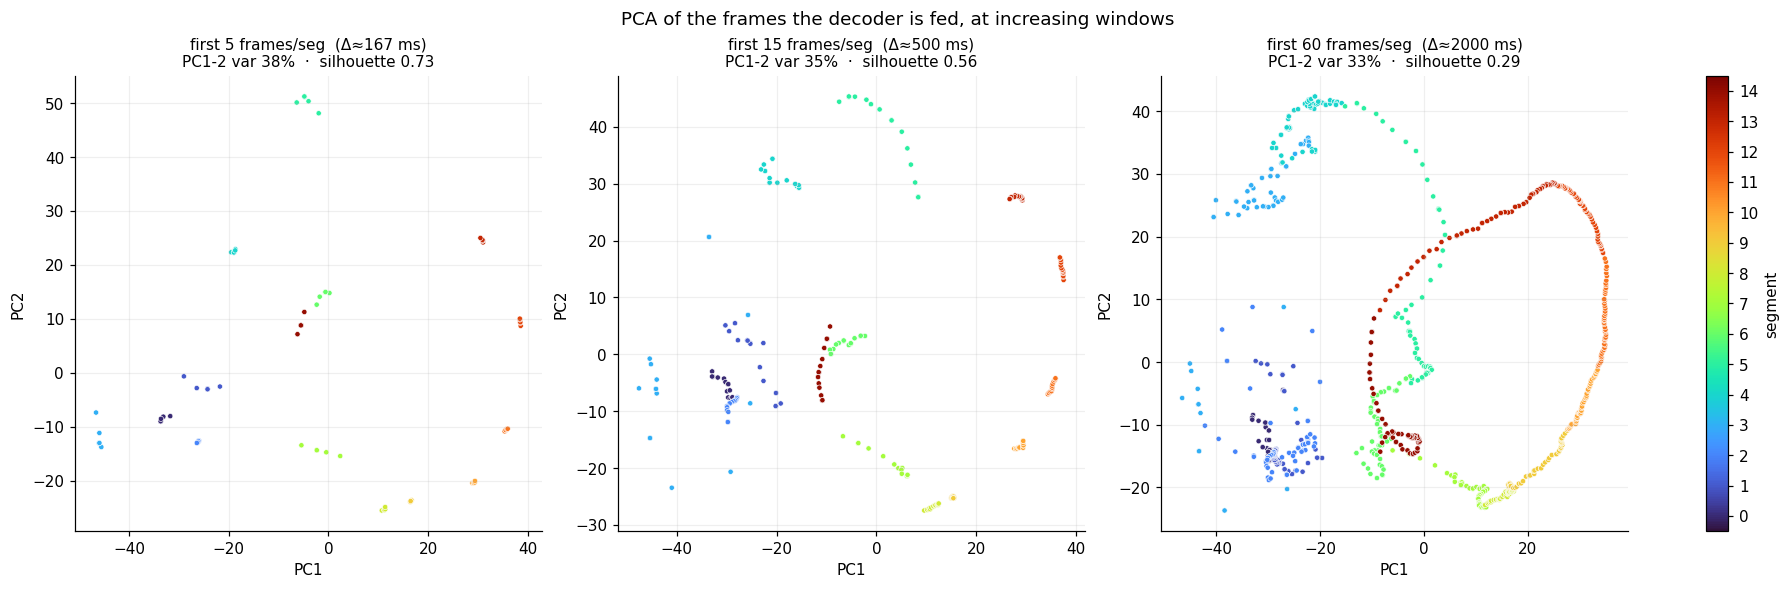

In [ ]:
snapshots = [5, 15, 60]      # frames/segment  →  ~160 ms, ~500 ms, ~2000 ms at 30 fps

fig, axes = plt.subplots(1, len(snapshots), figsize=(5.4 * len(snapshots), 5),
                         constrained_layout=True)  # <-- handles the colorbar cleanly


for ax, nf in zip(axes, snapshots):
    Z, seg_id, pca = pca_on_fed_frames(movie, K, frames_per_seg, nf)
    silhouette   = silhouette_score(Z, seg_id)                           # Z[:, :2] for silhouette_score on 1st 2 PCs
    var_pc12_explained  = 100 * pca.explained_variance_ratio_[:2].sum()  # % variance in the 2-D view
    
    sc = ax.scatter(Z[:, 0], Z[:, 1], c=seg_id, cmap="turbo",
                    s=12, alpha=1, edgecolors="white", linewidths=0.4,
                    vmin=-0.5, vmax=K - 0.5)
    ax.set_title(f"first {nf} frames/seg  (Δ≈{nf/FPS*1000:.0f} ms)\n"
                 f"PC1-2 var {var_pc12_explained:.0f}%  ·  silhouette {silhouette:.2f}", fontsize=10)
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.grid(alpha=0.2)

    var_pc10_explained = 100 * pca.explained_variance_ratio_[:10].sum()
    print(f"Variance explained by first 10 PCs for {nf} frames/seg: {var_pc10_explained:.1f}%")

color_bar = fig.colorbar(sc, ax=axes, label="segment", ticks=range(0, K, max(1, K // 8)))
fig.suptitle("PCA of the frames the decoder is fed, at increasing windows", y=1.04)
plt.show()

## Interpretation & caveats

- **Gap interpretation:** `gap_ms = Δ95_neural − Δ95_stim`. Large positive gaps mean a region's accumulation window is dominated by neural integration rather than by new stimulus content; if the gap grows up the hierarchy (VISp → VISam), that is integration-time lengthening over and beyond any stimulus effect
- **Response latency:** The sensory signal reaches higher areas tens of ms after VISp (Siegle et al. 2021, *Nature* 592:86–92, Fig. 4), but that offset is a *response latency* (retinal + thalamic + synaptic + intracortical processing), and not a computation-free transmission delay -> shouldn't be interpreted as pure axonal conduction
- **Shape, not level.** Stimulus and neural accuracies live in different feature spaces / sample regimes, so only the normalized-gain *timing* can be soundly compared, not absolute heights